# Modelagem: escolha do modelo e da métrica

Objetivo deste notebook: **decidir** qual algoritmo, qual métrica principal e quais hiperparâmetros usar. É um notebook de experimentação; o treino definitivo roda como código em `src/`, e este notebook só justifica as escolhas.

Fluxo:

1. Preparação (decisões da EDA) e split estratificado
2. Baseline e candidatos com validação cruzada **no treino**
3. Avaliação no teste (hold-out) apenas para reportar, não para escolher
4. Ajuste fino de hiperparâmetros dos modelos de árvore/boosting e escolha do modelo final
5. Análise de threshold e importância das features
6. Decisões finais

# 1 - Configuração do ambiente

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    average_precision_score,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42  # seed fixa para reprodutibilidade
TARGET = "Revenue"

# 2 - Preparação dos dados

Decisões tomadas na EDA aplicadas aqui:

- remover as linhas duplicadas antes do split (evita a mesma sessão em treino e teste)
- `Revenue` e `Weekend` como inteiro/categoria; códigos (`OperatingSystems`, `Browser`, `Region`, `TrafficType`) tratados como **categorias**, não como números

In [2]:
NUMERIC = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay",
]
CATEGORICAL = [
    "Month",
    "VisitorType",
    "Weekend",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
]

df = pd.read_csv("../data/source/online_shoppers_intention.csv")
print(f"Shape bruto: {df.shape}")

df = df.drop_duplicates().reset_index(drop=True)
df[TARGET] = df[TARGET].astype(int)
df[CATEGORICAL] = df[CATEGORICAL].astype(str)
print(f"Shape sem duplicatas: {df.shape}")
print(f"Taxa de compra: {df[TARGET].mean():.2%}")

Shape bruto: (12330, 18)
Shape sem duplicatas: (12205, 18)
Taxa de compra: 15.63%


## 2.1 - Split treino/teste (estratificado)

In [3]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"Treino: {X_train.shape} | taxa de compra: {y_train.mean():.2%}")
print(f"Teste : {X_test.shape} | taxa de compra: {y_test.mean():.2%}")

Treino: (9764, 17) | taxa de compra: 15.63%
Teste : (2441, 17) | taxa de compra: 15.65%


**Interpretação**:


- Após remover as 125 duplicatas ficam 12.205 sessões; split 80/20 estratificado (9.764 treino, 2.441 teste) mantém a taxa de compra em ~15,6% nos dois conjuntos
- O teste (~380 compras) é pequeno: métricas de um único hold-out têm ruído, por isso a **escolha do modelo usa a validação cruzada do treino** e o teste serve só para reportar

# 3 - Pipeline de pré-processamento e candidatos

In [4]:
def build_preprocessor(log_numeric: bool = False) -> ColumnTransformer:
    """Numéricas: (log1p opcional) + StandardScaler. Categóricas: one-hot."""
    numeric_steps = []
    if log_numeric:
        numeric_steps.append(
            ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one"))
        )
    numeric_steps.append(("scaler", StandardScaler()))

    return ColumnTransformer(
        [
            ("numeric", Pipeline(numeric_steps), NUMERIC),
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                CATEGORICAL,
            ),
        ]
    )


def build_pipeline(estimator, log_numeric: bool = False) -> Pipeline:
    return Pipeline(
        [
            ("preprocessor", build_preprocessor(log_numeric)),
            ("model", estimator),
        ]
    )


# XGBoost não tem class_weight: o equivalente é scale_pos_weight = negativos / positivos
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight (XGBoost): {scale_pos_weight:.2f}")

candidates = {
    "dummy (baseline trivial)": build_pipeline(DummyClassifier(strategy="prior")),
    "logistic_regression": build_pipeline(
        LogisticRegression(
            max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE
        )
    ),
    "logistic_regression + log1p": build_pipeline(
        LogisticRegression(
            max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE
        ),
        log_numeric=True,
    ),
    "random_forest": build_pipeline(
        RandomForestClassifier(
            n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE
        )
    ),
    "hist_gradient_boosting": build_pipeline(
        HistGradientBoostingClassifier(
            class_weight="balanced", random_state=RANDOM_STATE
        )
    ),
    "xgboost": build_pipeline(
        XGBClassifier(
            tree_method="hist",
            eval_metric="logloss",
            scale_pos_weight=scale_pos_weight,
            random_state=RANDOM_STATE,
        )
    ),
}
list(candidates)

scale_pos_weight (XGBoost): 5.40


['dummy (baseline trivial)',
 'logistic_regression',
 'logistic_regression + log1p',
 'random_forest',
 'hist_gradient_boosting',
 'xgboost']

Escolha dos candidatos:

- **Regressão logística**: baseline linear, interpretável. Testamos também com `log1p` nas numéricas, por causa da assimetria vista na EDA
- **Random Forest**: captura interações (ex.: `Month` x `VisitorType`) e é robusto a assimetria
- **HistGradientBoosting**: gradient boosting do próprio Scikit-Learn, rápido e forte em dados tabulares
- **XGBoost**: a implementação de gradient boosting mais usada no mercado (biblioteca externa, com API compatível com o Scikit-Learn)
- Todos tratam o desbalanceamento (~15% de compras): `class_weight="balanced"` nos modelos do Scikit-Learn e `scale_pos_weight` (negativos/positivos) no XGBoost

# 4 - Validação cruzada (apenas no treino)

In [5]:
SCORING = {
    "average_precision": "average_precision",  # PR-AUC
    "roc_auc": "roc_auc",
    "f1": "f1",
    "precision": "precision",
    "recall": "recall",
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, model in candidates.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
    row = {"modelo": name}
    for metric in SCORING:
        values = scores[f"test_{metric}"]
        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_std"] = values.std()
    rows.append(row)

cv_table = (
    pd.DataFrame(rows)
    .set_index("modelo")
    .sort_values("average_precision_mean", ascending=False)
)
cv_table.round(3)

,average_precision_mean,average_precision_std,roc_auc_mean,roc_auc_std,f1_mean,f1_std,precision_mean,precision_std,recall_mean,recall_std
modelo,,,,,,,,,,
hist_gradient_boosting,0.743,0.019,0.926,0.007,0.670,0.018,0.586,0.022,0.782,0.023
random_forest,0.733,0.018,0.927,0.004,0.682,0.019,0.646,0.022,0.724,0.031
xgboost,0.716,0.019,0.918,0.007,0.657,0.019,0.624,0.017,0.695,0.028
logistic_regression + log1p,0.663,0.023,0.916,0.008,0.646,0.014,0.545,0.016,0.794,0.019
logistic_regression,0.646,0.023,0.899,0.012,0.607,0.024,0.508,0.023,0.754,0.027
dummy (baseline trivial),0.156,0.000,0.500,0.000,0.000,0.000,0.000,0.000,0.000,0.000


In [6]:
# visão compacta: média ± desvio das 5 dobras
compact = pd.DataFrame(
    {
        metric: cv_table[f"{metric}_mean"].round(3).astype(str)
        + " ± "
        + cv_table[f"{metric}_std"].round(3).astype(str)
        for metric in SCORING
    }
)
compact

,average_precision,roc_auc,f1,precision,recall
modelo,,,,,
hist_gradient_boosting,0.743 ± 0.019,0.926 ± 0.007,0.67 ± 0.018,0.586 ± 0.022,0.782 ± 0.023
random_forest,0.733 ± 0.018,0.927 ± 0.004,0.682 ± 0.019,0.646 ± 0.022,0.724 ± 0.031
xgboost,0.716 ± 0.019,0.918 ± 0.007,0.657 ± 0.019,0.624 ± 0.017,0.695 ± 0.028
logistic_regression + log1p,0.663 ± 0.023,0.916 ± 0.008,0.646 ± 0.014,0.545 ± 0.016,0.794 ± 0.019
logistic_regression,0.646 ± 0.023,0.899 ± 0.012,0.607 ± 0.024,0.508 ± 0.023,0.754 ± 0.027
dummy (baseline trivial),0.156 ± 0.0,0.5 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0


**Interpretação**:


- **Baseline trivial** (`dummy`): PR-AUC = 0,156 (igual à taxa de compra) e ROC-AUC = 0,5. Todo modelo real precisa ser avaliado contra esse piso, e não contra a accuracy de 84%
- Os modelos de árvore/boosting superam a regressão logística com folga: PR-AUC de **0,743** (HistGradientBoosting), **0,733** (Random Forest) e **0,716** (XGBoost), contra 0,646 (logística)
- O `log1p` ajuda a logística (PR-AUC 0,646 para 0,663; ROC-AUC 0,899 para 0,916), confirmando a hipótese da EDA sobre a assimetria. Mesmo assim, não alcança os modelos de árvore
- Com parâmetros **padrão**, o XGBoost fica atrás dos outros dois, mas isso diz mais sobre os padrões da biblioteca (árvores de profundidade 6 e `learning_rate` 0,3, mais propensas a sobreajuste neste dado) do que sobre o algoritmo. A comparação justa é depois do ajuste (seção 6)
- HistGradientBoosting e Random Forest estão praticamente empatados com parâmetros padrão (diferença de 0,010, menor que o desvio entre dobras de ~0,02)

# 5 - Avaliação no teste (hold-out)

Cada candidato é treinado no treino completo e avaliado no teste, apenas para **reportar**. A escolha do modelo usa a validação cruzada acima, não o teste. Métricas de classe (F1, precision, recall) usam o threshold padrão de 0,5.

In [7]:
def evaluate(model, X_eval, y_eval, threshold: float = 0.5) -> dict:
    proba = model.predict_proba(X_eval)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        "average_precision": average_precision_score(y_eval, proba),
        "roc_auc": roc_auc_score(y_eval, proba),
        "f1": f1_score(y_eval, pred, zero_division=0),
        "precision": precision_score(y_eval, pred, zero_division=0),
        "recall": recall_score(y_eval, pred, zero_division=0),
    }


fitted = {name: model.fit(X_train, y_train) for name, model in candidates.items()}
test_table = pd.DataFrame(
    {name: evaluate(m, X_test, y_test) for name, m in fitted.items()}
).T
test_table.sort_values("average_precision", ascending=False).round(3)

,average_precision,roc_auc,f1,precision,recall
hist_gradient_boosting,0.736,0.929,0.659,0.564,0.793
random_forest,0.734,0.925,0.674,0.634,0.720
xgboost,0.726,0.923,0.656,0.612,0.707
logistic_regression + log1p,0.678,0.926,0.663,0.558,0.817
logistic_regression,0.663,0.910,0.618,0.505,0.796
dummy (baseline trivial),0.156,0.500,0.000,0.000,0.000


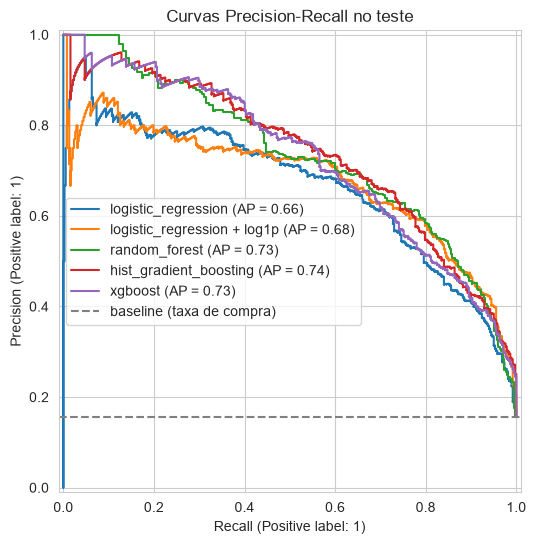

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))
for name, model in fitted.items():
    if name.startswith("dummy"):
        continue
    PrecisionRecallDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.axhline(y_test.mean(), color="gray", ls="--", label="baseline (taxa de compra)")
ax.set_title("Curvas Precision-Recall no teste")
ax.legend()
plt.show()

**Interpretação**:


- No teste a ordem se mantém: HistGradientBoosting e Random Forest empatados no topo (PR-AUC 0,736 e 0,734), seguidos do XGBoost (0,726) e, bem abaixo, a logística. O ranking é consistente com a validação cruzada
- A logística com `log1p` tem o maior recall (0,82), mas com precision baixa (0,56): ela "acerta" mais compradores às custas de mais falsos positivos
- Métricas de classe (F1, precision, recall) dependem do threshold de 0,5; PR-AUC e ROC-AUC não dependem

# 6 - Ajuste fino de hiperparâmetros

Com parâmetros padrão, os modelos de árvore/boosting ficam próximos entre si, e os padrões de cada biblioteca favorecem uns mais que outros (o XGBoost, por exemplo, usa árvores mais profundas e taxa de aprendizado maior). Para uma comparação justa, os **três modelos de árvore/boosting** passam pela mesma busca aleatória pequena (20 configurações, mesma validação cruzada, mesma métrica `average_precision`) e o modelo final é escolhido **depois do ajuste**.

In [9]:
SEARCH_SPACES = {
    "logistic_regression": {"model__C": [0.01, 0.1, 1, 10, 100]},
    "logistic_regression + log1p": {"model__C": [0.01, 0.1, 1, 10, 100]},
    "random_forest": {
        "model__n_estimators": [200, 300, 500],
        "model__max_depth": [None, 8, 12, 20],
        "model__min_samples_leaf": [1, 2, 5, 10],
        "model__max_features": ["sqrt", 0.5],
    },
    "hist_gradient_boosting": {
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_depth": [None, 3, 5],
        "model__max_leaf_nodes": [15, 31, 63],
        "model__min_samples_leaf": [20, 50, 100],
        "model__l2_regularization": [0.0, 0.1, 1.0],
    },
    "xgboost": {
        "model__n_estimators": [100, 200, 300],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_depth": [3, 4, 5, 6],
        "model__min_child_weight": [1, 5, 10],
        "model__subsample": [0.7, 0.85, 1.0],
        "model__colsample_bytree": [0.7, 0.85, 1.0],
        "model__reg_lambda": [1, 5, 10],
    },
}

TUNED_MODELS = ["random_forest", "hist_gradient_boosting", "xgboost"]

searches = {}
for name in TUNED_MODELS:
    searches[name] = RandomizedSearchCV(
        candidates[name],
        param_distributions=SEARCH_SPACES[name],
        n_iter=20,
        scoring="average_precision",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ).fit(X_train, y_train)

tuning_table = pd.DataFrame(
    {
        "PR-AUC CV (padrão)": {
            n: cv_table.loc[n, "average_precision_mean"] for n in TUNED_MODELS
        },
        "PR-AUC CV (ajustado)": {n: searches[n].best_score_ for n in TUNED_MODELS},
        "desvio (ajustado)": {
            n: searches[n].cv_results_["std_test_score"][searches[n].best_index_]
            for n in TUNED_MODELS
        },
    }
).sort_values("PR-AUC CV (ajustado)", ascending=False)
tuning_table.round(4)

,PR-AUC CV (padrão),PR-AUC CV (ajustado),desvio (ajustado)
hist_gradient_boosting,0.7430,0.7534,0.0193
xgboost,0.7162,0.7532,0.0189
random_forest,0.7331,0.7527,0.0216


**Interpretação**:


- Depois do ajuste os **três modelos empatam**: PR-AUC na validação cruzada de 0,7534 (HistGradientBoosting), 0,7532 (XGBoost) e 0,7527 (Random Forest), diferenças de ~0,001 contra um desvio de ~0,02 entre dobras. Ou seja, **não há diferença estatística entre eles** neste dataset
- O XGBoost é o que mais se beneficia do ajuste (0,716 para 0,753): os padrões dele não eram bons para este dado, mas com regularização adequada alcança os outros
- No teste a ordem é a mesma (0,757 / 0,753 / 0,747), mas a diferença também está dentro do ruído de um hold-out de ~380 compras
- Como o desempenho é equivalente, o critério de desempate passa a ser de **engenharia**: o HistGradientBoosting vem no Scikit-Learn (sem dependência extra), não exige `libomp` no Mac nem `libgomp1` na imagem Docker e treina mais rápido que o Random Forest. O XGBoost só se justificaria se ganhasse de forma clara, o que não ocorreu

In [10]:
# desempenho no teste dos modelos ajustados (apenas para reportar)
tuned_test_table = pd.DataFrame(
    {
        name: evaluate(searches[name].best_estimator_, X_test, y_test)
        for name in TUNED_MODELS
    }
).T
tuned_test_table.sort_values("average_precision", ascending=False).round(3)

,average_precision,roc_auc,f1,precision,recall
hist_gradient_boosting,0.757,0.938,0.664,0.540,0.861
xgboost,0.753,0.937,0.666,0.549,0.846
random_forest,0.747,0.934,0.664,0.551,0.835


## 6.1 - Seleção do modelo final

In [11]:
CHAMPION = tuning_table.index[0]
search = searches[CHAMPION]
tuned = search.best_estimator_

print(f"Modelo escolhido (maior PR-AUC na CV após ajuste): {CHAMPION}")
print(f"Melhor PR-AUC (CV): {search.best_score_:.3f}")
print("Melhores parâmetros:")
for param, value in search.best_params_.items():
    print(f"  {param}: {value}")

Modelo escolhido (maior PR-AUC na CV após ajuste): hist_gradient_boosting
Melhor PR-AUC (CV): 0.753
Melhores parâmetros:
  model__min_samples_leaf: 100
  model__max_leaf_nodes: 15
  model__max_depth: 5
  model__learning_rate: 0.05
  model__l2_regularization: 1.0


In [12]:
comparison = pd.DataFrame(
    {
        "padrão": evaluate(fitted[CHAMPION], X_test, y_test),
        "ajustado": evaluate(tuned, X_test, y_test),
    }
).T
comparison.round(3)

,average_precision,roc_auc,f1,precision,recall
padrão,0.736,0.929,0.659,0.564,0.793
ajustado,0.757,0.938,0.664,0.540,0.861


In [13]:
# top configurações da busca (para ver a sensibilidade aos hiperparâmetros)
results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
param_cols = [c for c in results.columns if c.startswith("param_")]
results[param_cols + ["mean_test_score", "std_test_score"]].head(8).round(3)

,param_model__min_samples_leaf,param_model__max_leaf_nodes,param_model__max_depth,param_model__learning_rate,param_model__l2_regularization,mean_test_score,std_test_score
11,100,15,5,0.05,1.0,0.753,0.019
6,100,63,5,0.05,1.0,0.753,0.020
19,50,15,5,0.05,0.1,0.752,0.020
0,20,63,5,0.03,0.0,0.751,0.020
16,100,15,5,0.10,1.0,0.751,0.020
13,100,63,None,0.03,1.0,0.751,0.018
10,20,15,5,0.05,0.0,0.750,0.021
4,50,31,5,0.10,1.0,0.750,0.020


**Interpretação**:


- Para o modelo escolhido, o ajuste fino melhora pouco: PR-AUC na validação cruzada de 0,743 para 0,753, dentro do desvio entre dobras (~0,02). As oito melhores configurações da busca ficam todas entre 0,750 e 0,753, ou seja, o modelo é **pouco sensível** aos hiperparâmetros
- O padrão dos melhores parâmetros é de um modelo mais **regularizado**: árvores rasas (`max_depth` 5), folhas grandes (`min_samples_leaf` 100) e `l2_regularization` 1,0
- No teste a PR-AUC sobe de 0,736 para 0,757 e o recall de 0,79 para 0,86, mas a precision cai (0,56 para 0,54) com o threshold padrão. O ganho no teste (um único hold-out) deve ser lido com cautela

# 7 - Threshold de decisão

Com `class_weight="balanced"` o modelo já é empurrado para a classe positiva, mas o threshold de 0,5 não é necessariamente o melhor. Para não olhar o teste, o threshold é escolhido com **predições out-of-fold no treino** e só então aplicado no teste.

Threshold que maximiza F1 (OOF no treino): 0.728 (F1 = 0.695)


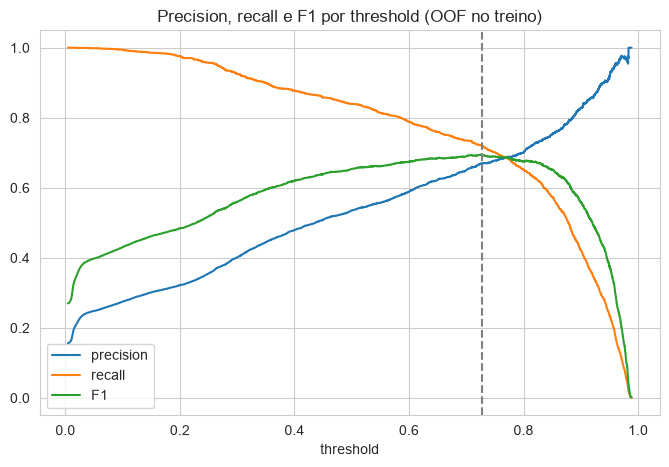

In [14]:
oof_proba = cross_val_predict(
    tuned, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_train, oof_proba)
f1_scores = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)

best_idx = int(np.argmax(f1_scores))
BEST_THRESHOLD = float(thresholds[best_idx])
print(
    f"Threshold que maximiza F1 (OOF no treino): {BEST_THRESHOLD:.3f} (F1 = {f1_scores[best_idx]:.3f})"
)

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precision[:-1], label="precision")
plt.plot(thresholds, recall[:-1], label="recall")
plt.plot(thresholds, f1_scores, label="F1")
plt.axvline(BEST_THRESHOLD, color="gray", ls="--")
plt.xlabel("threshold")
plt.title("Precision, recall e F1 por threshold (OOF no treino)")
plt.legend()
plt.show()

In [15]:
pd.DataFrame(
    {
        "threshold 0.5": evaluate(tuned, X_test, y_test, threshold=0.5),
        f"threshold {BEST_THRESHOLD:.2f}": evaluate(
            tuned, X_test, y_test, threshold=BEST_THRESHOLD
        ),
    }
).T.round(3)

,average_precision,roc_auc,f1,precision,recall
threshold 0.5,0.757,0.938,0.664,0.540,0.861
threshold 0.73,0.757,0.938,0.694,0.663,0.728


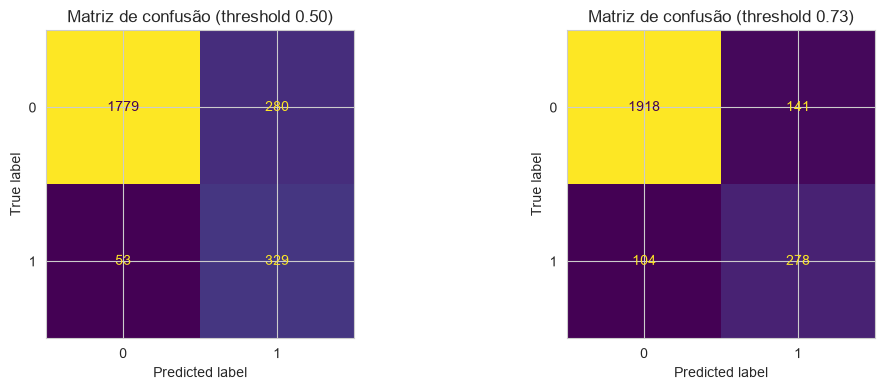

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, threshold in zip(axes, [0.5, BEST_THRESHOLD]):
    pred = (tuned.predict_proba(X_test)[:, 1] >= threshold).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, colorbar=False)
    ax.set_title(f"Matriz de confusão (threshold {threshold:.2f})")
plt.tight_layout()
plt.show()

**Interpretação**:


- O threshold que maximiza o F1 nas predições out-of-fold do treino é **0,73**, bem acima de 0,5. Com `class_weight="balanced"` o modelo é empurrado para a classe positiva, e subir o threshold recupera precision
- No teste, com o threshold 0,73: F1 sobe de 0,664 para 0,694, precision de 0,54 para 0,66 e o recall cai de 0,86 para 0,73. PR-AUC e ROC-AUC não mudam, pois não dependem do threshold
- A escolha do threshold depende do custo de negócio: com recall alto (threshold baixo) alcançamos mais compradores, mas gastamos ação de marketing com mais não compradores. F1 é apenas um critério neutro para este desafio

# 8 - Importância das features

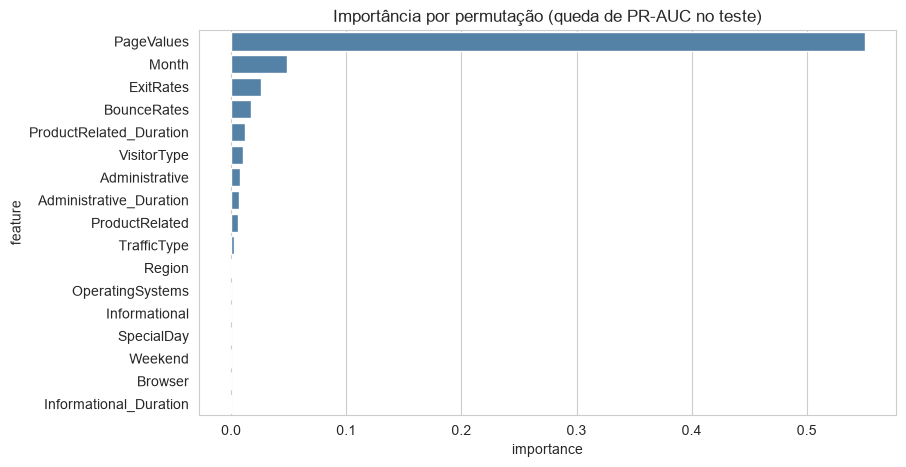

,feature,importance,std
8,PageValues,0.5502,0.0065
10,Month,0.0486,0.0053
7,ExitRates,0.0260,0.0058
6,BounceRates,0.0176,0.0072
5,ProductRelated_Duration,0.0119,0.0034
15,VisitorType,0.0106,0.0043
0,Administrative,0.0079,0.0050
1,Administrative_Duration,0.0071,0.0039
4,ProductRelated,0.0060,0.0027
14,TrafficType,0.0029,0.0020


In [17]:
importance = permutation_importance(
    tuned,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
importance_df = pd.DataFrame(
    {
        "feature": X_test.columns,
        "importance": importance.importances_mean,
        "std": importance.importances_std,
    }
).sort_values("importance", ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(data=importance_df, y="feature", x="importance", color="steelblue")
plt.title("Importância por permutação (queda de PR-AUC no teste)")
plt.show()
importance_df.round(4)

**Interpretação**:


- **`PageValues` domina**: a permutação dessa feature derruba a PR-AUC em ~0,55, mais de dez vezes qualquer outra. Isso confirma a EDA e o alerta de possível leakage parcial (a variável mede o valor de páginas visitadas antes de uma transação)
- Em segundo lugar vêm `Month` (0,049), `ExitRates` (0,026) e `BounceRates` (0,018)
- `Region`, `OperatingSystems`, `Browser`, `Weekend`, `SpecialDay` e `Informational*` têm importância ~0 (ou levemente negativa, que é ruído), coerente com a baixa relação com o target vista na EDA. Não prejudicam o modelo, mas poderiam ser removidas sem perda; mantemos para o pipeline genérico e simples

# 9 - Decisões finais

In [18]:
final_decision = {
    "algoritmo": CHAMPION,
    "metrica_selecao": "average_precision (PR-AUC)",
    "seed": RANDOM_STATE,
    "split": {"test_size": 0.2, "estratificado": True, "remove_duplicatas": True},
    "cv_folds": 5,
    "threshold": round(BEST_THRESHOLD, 3),
    "melhores_hiperparametros": search.best_params_,
}
final_decision

{'algoritmo': 'hist_gradient_boosting',
 'metrica_selecao': 'average_precision (PR-AUC)',
 'seed': 42,
 'split': {'test_size': 0.2, 'estratificado': True, 'remove_duplicatas': True},
 'cv_folds': 5,
 'threshold': 0.728,
 'melhores_hiperparametros': {'model__min_samples_leaf': 100,
  'model__max_leaf_nodes': 15,
  'model__max_depth': 5,
  'model__learning_rate': 0.05,
  'model__l2_regularization': 1.0}}

## Resumo das decisões

**Modelo**: `HistGradientBoostingClassifier` (Scikit-Learn), com `class_weight="balanced"`. Motivos:

- Maior PR-AUC na validação cruzada depois do ajuste (0,7534), **tecnicamente empatado** com o XGBoost (0,7532) e o Random Forest (0,7527): a diferença é muito menor que o desvio entre dobras (~0,02)
- Desempate por engenharia: dependência nativa do Scikit-Learn (sem `xgboost`, `libomp` ou `libgomp1`), treino rápido e imagem Docker mais simples
- Muito acima da regressão logística (0,663 com `log1p`), que serve como baseline interpretável e do baseline trivial (0,156)
- XGBoost e Random Forest continuam como alternativas válidas, trocáveis por configuração

**Métrica principal de seleção**: `average_precision` (PR-AUC). Motivo: dataset desbalanceado (~15,6% positivos), a métrica foca na classe positiva e não depende de threshold. Métricas de apoio logadas: ROC-AUC, F1, precision e recall. Accuracy não é usada (baseline trivial = 84%).

**Hiperparâmetros** (melhores da busca): `learning_rate=0.05`, `max_depth=5`, `max_leaf_nodes=15`, `min_samples_leaf=100`, `l2_regularization=1.0`. Pouca sensibilidade: qualquer configuração parecida serve.

**Protocolo**: remover duplicatas, split 80/20 estratificado, validação cruzada estratificada de 5 dobras, seed 42.

**Threshold**: 0,73 (maximiza F1 nas predições out-of-fold do treino). É um parâmetro configurável, e as métricas devem ser logadas também com o threshold padrão de 0,5.

**Pré-processamento**: `StandardScaler` nas numéricas e one-hot nas categóricas, dentro de um `Pipeline` único com o modelo. O boosting não precisa de escala, mas mantemos o mesmo pré-processamento para o algoritmo ser trocável por configuração (a logística, por exemplo, ganha com `log1p`).

## Limitações e lições

- `PageValues` concentra o poder preditivo (possível leakage parcial)
- O hold-out de teste é pequeno (~380 compras): diferenças de ~0,01 em PR-AUC entre os modelos não são significativas
- Comparar algoritmos só com parâmetros padrão pode levar a conclusões enganosas (o XGBoost parecia o pior e empatou depois do ajuste)
- Várias features têm importância ~0 e poderiam ser descartadas